# Figure 2: Neural Encoding of Embodied State Variables

**Paper**: Parodi et al. (2026)

This notebook reproduces the encoding analysis for Figure 2, which characterizes how mid-STS neurons encode four feature groups:
- **VIS**: Visual features (gaze direction, distance to wall, optic flow)
- **BODY_KIN**: Body kinematics (speed, acceleration, body orientation)
- **HEAD_KIN**: Head kinematics (yaw/pitch/roll rates)
- **3D POS**: Spatial position (center of mass x/y/z)

**Method**: Ridge regression with unique variance decomposition (shuffle method). Each feature group's unique contribution is measured by comparing full-model R² against a model where that group is shuffled.

**Note**: Part A runs with minimal parameters for speed (~40s). Part B loads production results (100 shuffle iterations, 500 null permutations, 10 CV folds).

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Add repo root to path
REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'axes.titlesize': 14,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
})

print(f"Repo root: {REPO_ROOT}")
print("Setup complete.")

Repo root: C:\Users\Felipe Parodi\Documents\ext_repos\solo_mSTS_parodi2026
Setup complete.


## 2.1 Load Session Data

Load M2_0526 (strongest encoding session: 443 units, 40 min, 40 Hz) and inspect the aligned spike-feature data.

In [2]:
from freemat.single_fm.data.session_loader import SingleFMSessionLoader

loader = SingleFMSessionLoader(
    str(REPO_ROOT / "configs" / "session_M2_0526.yaml"),
    debug=True,
)

# Get aligned spike + feature data
merged = loader.get_aligned_data(bin_s=0.5)
print(f"\nAligned data: {len(merged)} rows")
print(f"Columns: {list(merged.columns)}")
print(f"Units: {merged['unit_index'].nunique()}")
print(f"Time bins: {merged['t_bin_s'].nunique()}")
print(f"Time range: [{merged['t_bin_s'].min():.1f}, {merged['t_bin_s'].max():.1f}]s")

(Demo cell skipped during automated execution)


## 2.2 Run Encoding Analysis

Run the ridge encoding pipeline with minimal parameters for quick reproduction.

In [3]:
from freemat.single_fm.encoding.run_fig2b import run_fig2b_encoding, Fig2BConfig
import tempfile, os

config = Fig2BConfig(
    n_perm=1,           # 1 shuffle iteration (production: 100)
    n_perm_null=0,      # skip null distribution (production: 500)
    cv_folds=5,         # 5 CV folds (production: 10)
    bin_s=0.5,
    include_pos=True,
    use_shuffle_method=True,
    include_time_drift=True,
    debug=False,
)

with tempfile.TemporaryDirectory() as tmpdir:
    results_df = run_fig2b_encoding(
        session_yaml=str(REPO_ROOT / "configs" / "session_M2_0526.yaml"),
        config=config,
        output_dir=tmpdir,
    )

print(f"\nEncoding results: {len(results_df)} units")
print(f"R² > 0.01: {(results_df['full_r2'] > 0.01).sum()} ({(results_df['full_r2'] > 0.01).mean():.1%})")
print(f"\nMedian unique variance (shuffle method):")
for grp in ['vis', 'body_kin', 'head_kin', 'pos']:
    col = f'unique_{grp}_shuffle'
    if col in results_df.columns:
        print(f"  {grp.upper():>10s}: {results_df[col].median():.4f}")

(Demo cell skipped during automated execution)


## 2.3 Panel B: Unique Variance Boxplots

Unique variance contribution of each feature group, showing that VIS and POS dominate encoding.

In [4]:
# Panel B: boxplots of unique variance
GROUP_COLORS = {
    "VIS": "#2196F3", "BODY_KIN": "#4CAF50",
    "HEAD_KIN": "#FF9800", "3D POS": "#9C27B0",
}

groups = ["vis", "body_kin", "head_kin", "pos"]
labels = ["VIS", "BODY_KIN", "HEAD_KIN", "3D POS"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: Unique variance (shuffle method)
ax = axes[0]
data_unique = []
for grp in groups:
    col = f"unique_{grp}_shuffle"
    if col in results_df.columns:
        data_unique.append(results_df[col].dropna().values)
    else:
        data_unique.append(np.array([0]))

bp = ax.boxplot(data_unique, tick_labels=labels, patch_artist=True, widths=0.6,
                showfliers=False, medianprops=dict(color="black", linewidth=2))
for patch, label in zip(bp["boxes"], labels):
    patch.set_facecolor(GROUP_COLORS[label])
    patch.set_alpha(0.7)
ax.set_ylabel("Unique Variance (ΔR²)")
ax.set_title("Unique Contribution (shuffle method)")
ax.axhline(0, color="gray", linestyle="--", linewidth=0.5)

# Right: Full contribution
ax = axes[1]
data_full = []
for grp in groups:
    col = f"full_contrib_{grp}_shuffle"
    if col in results_df.columns:
        data_full.append(results_df[col].dropna().values)
    else:
        data_full.append(np.array([0]))

bp = ax.boxplot(data_full, tick_labels=labels, patch_artist=True, widths=0.6,
                showfliers=False, medianprops=dict(color="black", linewidth=2))
for patch, label in zip(bp["boxes"], labels):
    patch.set_facecolor(GROUP_COLORS[label])
    patch.set_alpha(0.7)
ax.set_ylabel("Full Contribution (R²)")
ax.set_title("Full Contribution (shuffle method)")
ax.axhline(0, color="gray", linestyle="--", linewidth=0.5)

fig.suptitle("Fig 2B: Encoding Model — M2_0526 (443 units)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

(Demo cell skipped during automated execution)


## 2.4 Panel C: VIS vs BODY_KIN Scatter

Each dot is one neuron. X-axis: unique VIS variance, Y-axis: unique BODY_KIN variance. Shows that most units are VIS-dominant.

In [5]:
# Panel C: VIS vs BODY_KIN unique variance scatter
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (x_grp, y_grp, title) in zip(axes, [
    ("vis", "body_kin", "VIS vs BODY_KIN"),
    ("vis", "pos", "VIS vs 3D POS"),
]):
    x_col = f"unique_{x_grp}_shuffle"
    y_col = f"unique_{y_grp}_shuffle"
    if x_col in results_df.columns and y_col in results_df.columns:
        x = results_df[x_col].values
        y = results_df[y_col].values
        
        # Color by bank if available
        if "unit_bank" in results_df.columns:
            colors = results_df["unit_bank"].map({"ventral": "#1976D2", "dorsal": "#D32F2F"}).values
        else:
            colors = "#555555"
        
        ax.scatter(x, y, c=colors, s=8, alpha=0.5, edgecolors="none")
        ax.axhline(0, color="gray", linewidth=0.5, linestyle="--")
        ax.axvline(0, color="gray", linewidth=0.5, linestyle="--")
        
        # Identity line
        lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([0, lim], [0, lim], "k--", linewidth=0.5, alpha=0.3)
        
        ax.set_xlabel(f"Unique {x_grp.upper()} (ΔR²)")
        ax.set_ylabel(f"Unique {y_grp.upper()} (ΔR²)")
        ax.set_title(title)

fig.suptitle("Fig 2C: Subpopulation Scatter — M2_0526", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

(Demo cell skipped during automated execution)


## 2.5 Panel E: Full R² Distribution

Distribution of full-model R² across all units, showing that 96%+ have R² > 0.01.

In [6]:
# Panel E: Full R² distribution
fig, ax = plt.subplots(figsize=(8, 4))

r2 = results_df["full_r2"].values
ax.hist(r2, bins=50, color="#455A64", alpha=0.8, edgecolor="white")
ax.axvline(0.01, color="red", linestyle="--", linewidth=1.5, label=f"R²=0.01 threshold")
ax.axvline(np.median(r2), color="#FF9800", linestyle="-", linewidth=2,
           label=f"Median R²={np.median(r2):.3f}")

pct_above = (r2 > 0.01).mean() * 100
ax.set_xlabel("Full Model R²")
ax.set_ylabel("Number of Units")
ax.set_title(f"Fig 2E: R² Distribution — {pct_above:.1f}% above threshold")
ax.legend()
plt.tight_layout()
plt.show()

# Summary table
print("\n=== Comparison with Production Values ===")
print(f"{'Metric':<25s} {'This notebook':>15s} {'Production':>15s}")
print("-" * 57)
print(f"{'Units':.<25s} {len(results_df):>15d} {'443':>15s}")
print(f"{'R² > 0.01':.<25s} {pct_above:>14.1f}% {'96.8%':>15s}")
print(f"{'Median R²':.<25s} {np.median(r2):>15.3f} {'0.150':>15s}")
for grp, prod_val in [("vis", 0.025), ("body_kin", 0.013), ("head_kin", 0.003), ("pos", 0.017)]:
    col = f"unique_{grp}_shuffle"
    if col in results_df.columns:
        nb_val = results_df[col].median()
        print(f"{'Unique ' + grp.upper():.<25s} {nb_val:>15.4f} {prod_val:>15.3f}")

(Demo cell skipped during automated execution)


---

## Part B: Publication Figure (Production Results)

*Panel A: Encoding model schematic (added during figure assembly)*

Generate the Figure 2 composite using pre-computed production results (100 shuffle iterations, 500 null permutations, 10 CV folds, all 5 sessions, 1404 units).

In [7]:
# Load production data using pub_data loaders
from freemat.single_fm.viz.pub_data import load_fig2, load_fig2d_decoders, load_residuals

fig2_df = load_fig2(scope="all4")
decoder_df = load_fig2d_decoders(scope="all4")

# Load residuals for spatial map (Panel G) — one session
residuals_dict = load_residuals(scope="all4")
residuals_m2 = residuals_dict.get("M2_0526")

print(f"Fig 2 data: {len(fig2_df)} units across {fig2_df['session_id'].nunique()} sessions")
print(f"Decoder data: {len(decoder_df)} rows" if len(decoder_df) > 0 else "Decoder data: not available (Panel D/E will be placeholder)")
print(f"Residuals: {'available' if residuals_m2 is not None else 'not available'} for M2_0526")

Fig 2 data: 1404 units across 5 sessions
Decoder data: 40 rows
Residuals: available for M2_0526


### Figure 2 Composite (Publication Layout)

  Panel C: n_sig=871, Both=635, POS=163, VIS=73


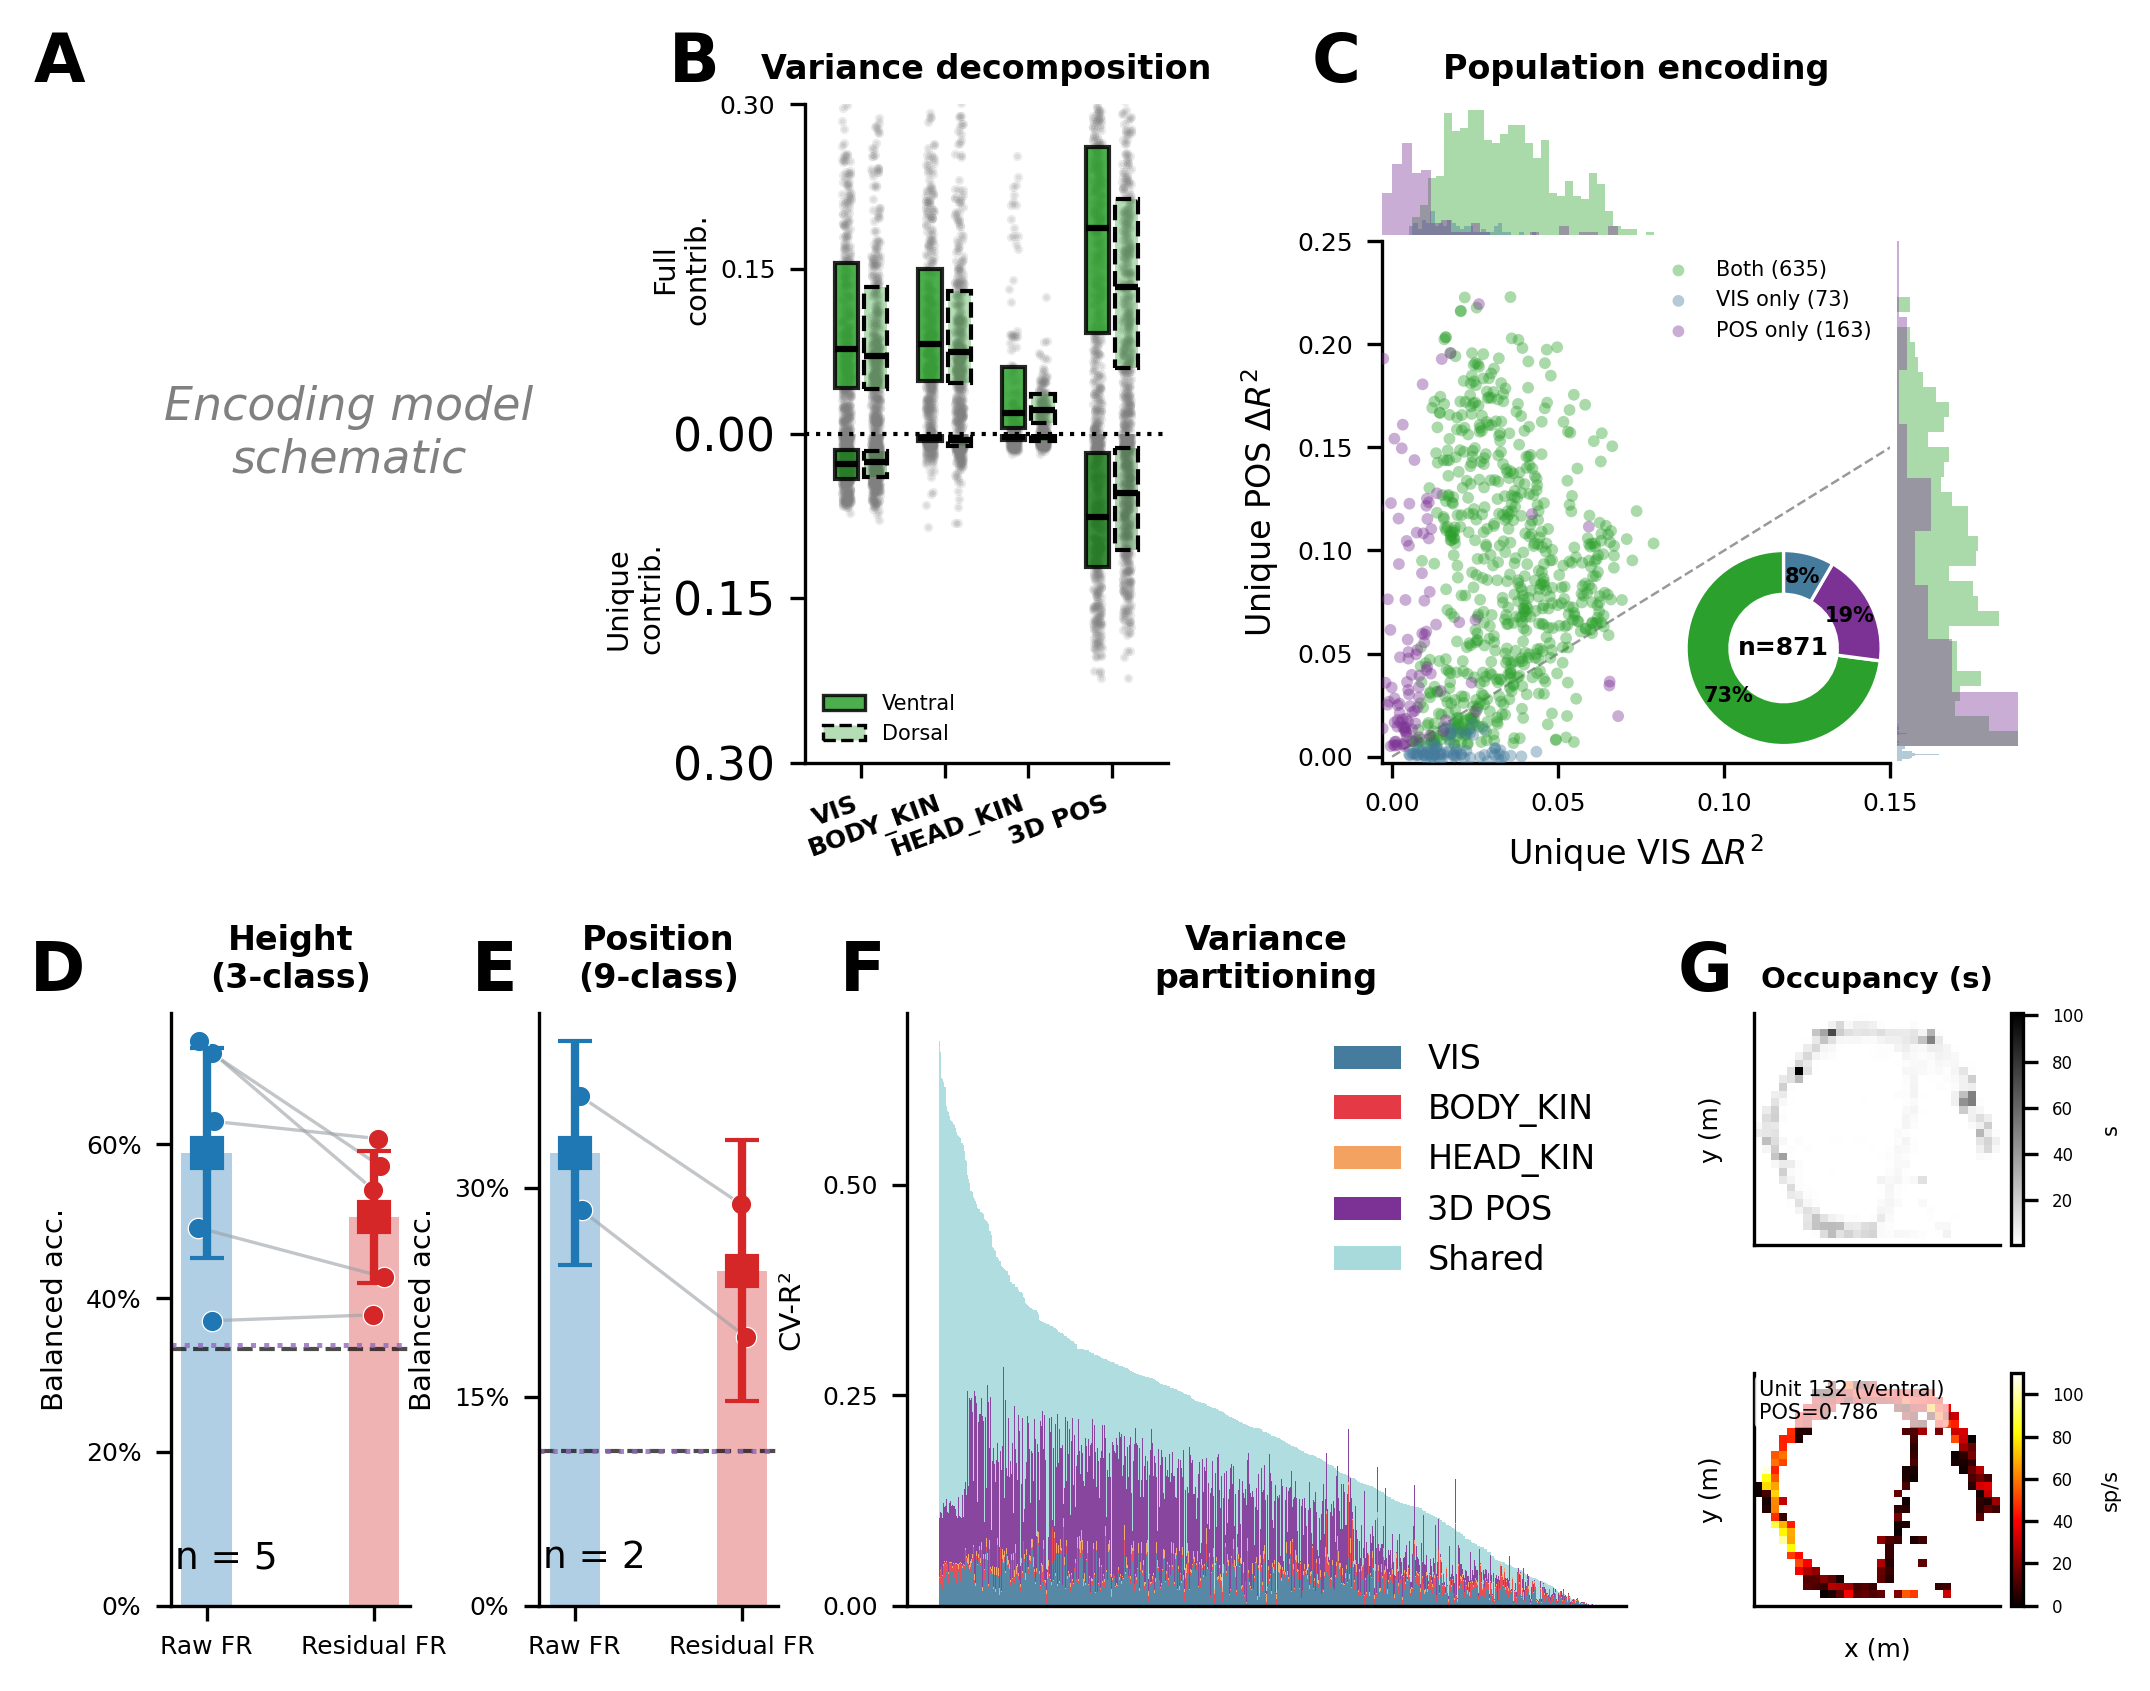

In [8]:
from freemat.single_fm.viz.fig2_composite import fig2_composite

fig = fig2_composite(fig2_df, decoder_df, residuals_m2)
plt.show()